# Analysis 1 — Treasury Market Conditions and Scenarios

## Setup — FRED observations

In [1]:
from pathlib import Path
from bondview.data.fred import FredDataManager
from bondview.presentation.widgets import DateRangePicker
from bondview import market

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOT_DIR = PROJECT_ROOT / "data/fred"
fred = FredDataManager(SNAPSHOT_DIR, env_path=PROJECT_ROOT / ".env")

### Download

In [ ]:
FRED_SERIES = (
    "DGS2", "DGS10", "DGS30",
    "THREEFY2", "THREEFYTP2", "THREEFY10", "THREEFYTP10",
)
start = None
end = None
downloaded = fred.download(series_ids=FRED_SERIES, start=start, end=end)

In [ ]:
# Optional inspection; downloaded is also a DataFrame.
#fred.report(series_ids='DGS10')  
fred.report()

In [ ]:
fred.save()

### Load Treasury observations

Required data setup for A and C; no KW inputs are needed.

In [3]:
observations = fred.load(series_ids=["DGS2", "DGS10", "DGS30"])
fred.report()

FRED observations (file)
Series ID             Nonmissing
DGS2                     12,597
DGS10                    16,189
DGS30                    12,419
Complete shared observations: 12,419


## A. Yield-curve conditions and movements

Examine 2Y, 10Y, and 30Y Treasury yields before selecting the interval for movement analysis.

### Treasury yield history

Inspect the available 2Y, 10Y, and 30Y yields before choosing dates. Optionally pass start/end to `show_history()` for a narrower chart.

In [5]:
date_range = DateRangePicker(observations)

In [9]:
date_range

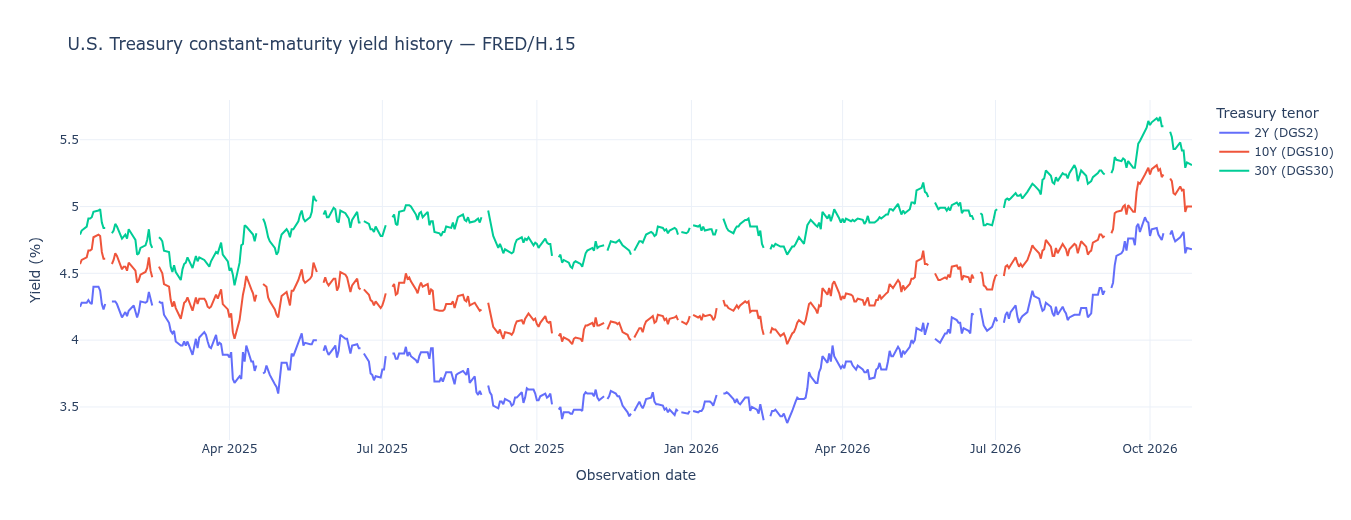

In [10]:
curve_analysis = market.curve(observations)
curve_analysis.show_history(*date_range.get_dates())

### Treasury yield and curve movements

Choose the date interval, calculate yield and spread changes, classify curve movements, and display the formatted table and interpretation. The numerical DataFrame is retained as `curve_analysis.result` without recalculation.

In [5]:
date_range = DateRangePicker(observations)

In [6]:
date_range

In [11]:
curve_analysis.analyze(
    *date_range.get_dates(),
    yield_change_tolerance_bp=5,
    slope_tolerance_bp=5,
    formatted=True,
)

,2025-01-02,2026-10-26,Change,Curve configuration,Movement / regime
Treasury measure,,,,,
2Y yield,4.25%,4.68%,+43 bp,—,Yield rose
10Y yield,4.57%,5.00%,+43 bp,—,Yield rose
30Y yield,4.79%,5.31%,+52 bp,—,Yield rose
10Y−2Y spread,+32 bp,+32 bp,+0 bp,Upward-sloping → Upward-sloping,Yields rose; little slope change
30Y−10Y spread,+22 bp,+31 bp,+9 bp,Upward-sloping → Upward-sloping,Bear steepening


Greatest upward yield movement among available tenors: 30Y (+52 bp). 10Y−2Y spread: Yields rose; little slope change. 30Y−10Y spread: Bear steepening. These are net endpoint movements, not the full path or a forecast.

In [ ]:
# Optional: inspect the stored numerical DataFrame without recalculation.
# curve_analysis.result

## B. Expected short rates and term premiums

*Load KW model estimates*

In [12]:
kw_observations = fred.load(
    series_ids=["THREEFY2", "THREEFYTP2", "THREEFY10", "THREEFYTP10"]
)

### 2Y and 10Y yield decomposition

In [13]:
kw_date_range = DateRangePicker(kw_observations)

In [16]:
kw_date_range

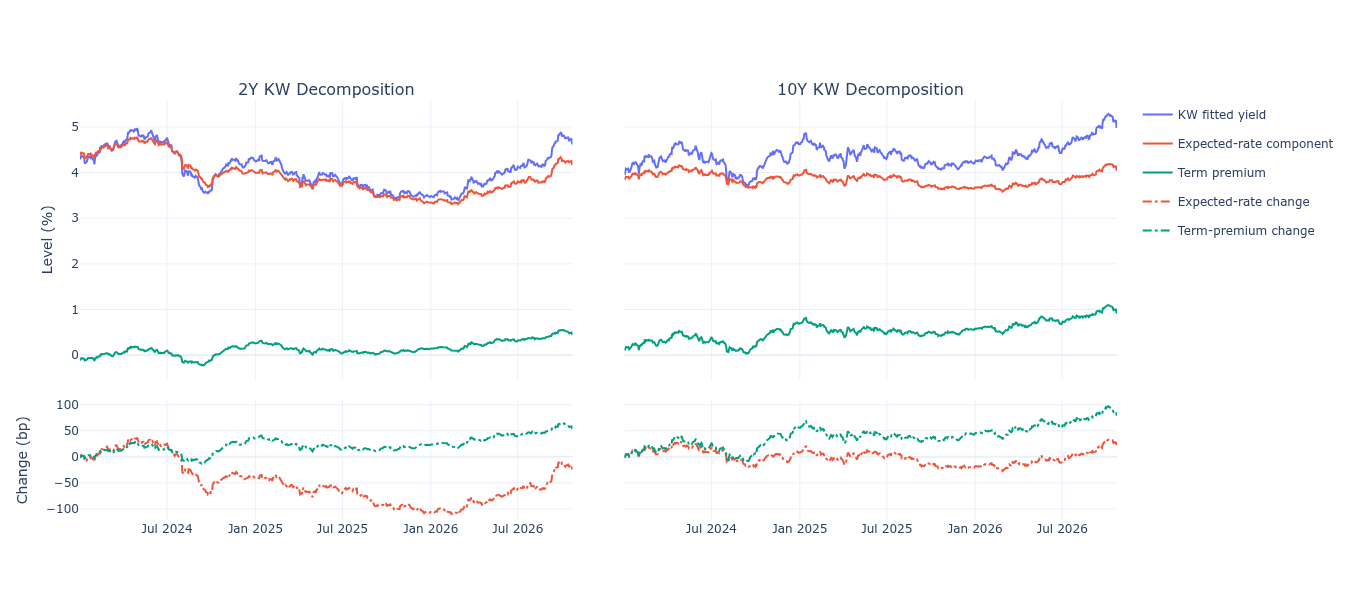

In [17]:
yield_decomposition = market.decomposition(kw_observations, *kw_date_range.get_dates())
decomposition_figure = yield_decomposition.show(width=1300, height=600)

## C. Conditional joint yield movements

Run Setup (load Treasury observations) and this section independently of A/B. Select whole historical intervals matching an inclusive 2Y or 10Y change range.

In [12]:
condition_tenor = "DGS10"
lower_bp, upper_bp = -25, 25
horizon_months = 6
sampling_step_observations = 1  # E.g. 5 or 20 complete observations
reference_start = None  # Earliest complete common observation
reference_end = None    # Latest complete common observation

### Complete scenario set

Candidate endpoints are complete Treasury observation dates supporting the calendar-month horizon. Starting at the oldest candidate, select every `sampling_step_observations`-th date before conditioning. A step counts complete observations, not calendar days. Appending later observations preserves earlier endpoint selections when earlier history is unchanged. Results are returned newest first. Each window still uses its first and last complete in-window observations and rejects fewer than two observations or more than seven days of combined endpoint shortfall. No outside-window search or yield filling is used; actual/intended dates, elapsed days and shortfall remain available for audit.

In [13]:
yield_scenarios = market.scenarios(
    observations,
    condition_tenor=condition_tenor,
    lower_bp=lower_bp, upper_bp=upper_bp,
    horizon_months=horizon_months, sampling_step_observations=sampling_step_observations,
    reference_start=reference_start, reference_end=reference_end,
)
joint_scenarios = yield_scenarios.scenarios
joint_scenarios

,scenario_id,start_date,target_end_date,end_date,elapsed_days,DGS2_change_bp,DGS10_change_bp,DGS30_change_bp,target_start_date,shortfall_days
0,UST_20260120_20260717,2026-01-20,2026-07-17,2026-07-17,178,58.0,25.0,15.0,2026-01-17,3
1,UST_20251226_20260626,2025-12-26,2026-06-26,2026-06-26,182,61.0,24.0,6.0,2025-12-26,0
2,UST_20251110_20260508,2025-11-10,2026-05-08,2026-05-08,179,32.0,25.0,24.0,2025-11-08,2
3,UST_20251106_20260506,2025-11-06,2026-05-06,2026-05-06,181,30.0,25.0,25.0,2025-11-06,0
4,UST_20251017_20260417,2025-10-17,2026-04-17,2026-04-17,182,25.0,24.0,28.0,2025-10-17,0
...,...,...,...,...,...,...,...,...,...,...
3277,UST_19770222_19770819,1977-02-22,1977-08-19,1977-08-19,178,58.0,-2.0,-9.0,1977-02-19,3
3278,UST_19770218_19770818,1977-02-18,1977-08-18,1977-08-18,181,62.0,1.0,-5.0,1977-02-18,0
3279,UST_19770217_19770817,1977-02-17,1977-08-17,1977-08-17,181,73.0,18.0,5.0,1977-02-17,0
3280,UST_19770216_19770816,1977-02-16,1977-08-16,1977-08-16,181,72.0,14.0,7.0,1977-02-16,0


### Descriptive statistical summary

Marginal quantiles summarize the set; they do not form additional joint scenarios. Overlapping-window counts are descriptive, not independent event frequencies or forecast probabilities.

In [14]:
_ = yield_scenarios.show_summary()

Condition: 10Y change [-25, 25] bp (inclusive). Horizon: 6 calendar months; endpoint step: 1 complete observations. Complete reference history: 1977-02-15 to 2026-10-26. Selected scenarios: 3282 / 12295 eligible windows.

,Minimum (bp),P10 (bp),Median (bp),P90 (bp),Maximum (bp)
Treasury tenor,,,,,
2Y,-259.0,-59.0,1.0,60.0,135.0
10Y,-25.0,-21.0,-2.0,20.0,25.0
30Y,-76.0,-31.0,-2.0,26.0,93.0


Statistics are in bp. Overlapping intervals and marginal quantiles are descriptive, not independent event frequencies or forecast probabilities. Endpoints are sampled from the earliest complete date supporting the horizon, before conditioning. The step counts complete observations, not calendar days. Window endpoints are the first and last complete observations inside each intended calendar-month window. Windows with fewer than two observations or over seven days of combined endpoint shortfall are excluded.

### Joint yield changes

Color identifies the conditioning tenor. Hover retains historical interval dates and elapsed days.

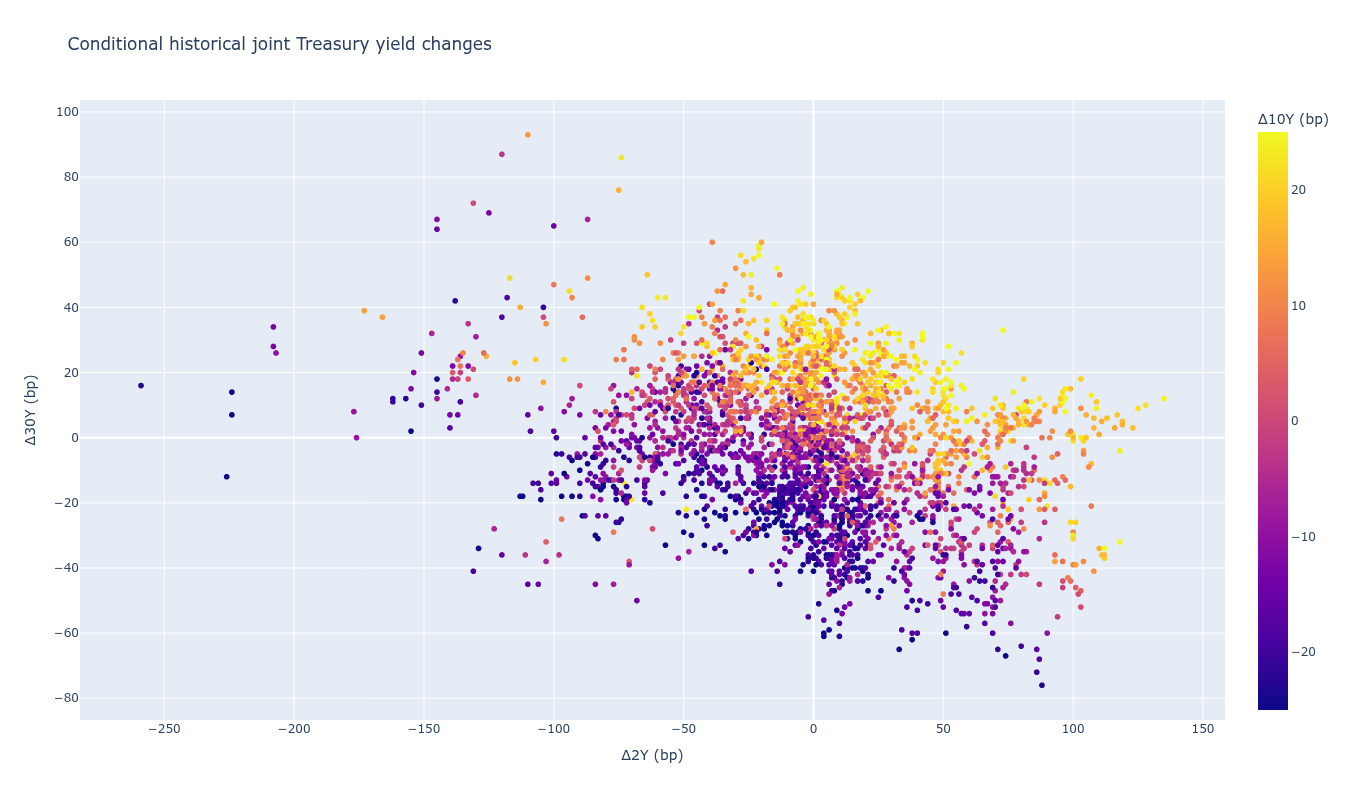

In [16]:
yield_scenarios.show_plot(height=800, width=800)